# F01.03 · Lanzador: visualización de una crisis de cada tipo

> 🧭 **En 30 segundos**
> - **Para qué:** ejecutar el notebook **F01.03v** una vez por cada tipo de crisis, sin mantener 7 copias.
> - **Entra:** **F01.03v** + la lista de tipos de `tipos_crisis.py` → **Sale:** una copia ejecutada del **F01.03v** por tipo, con sus figuras, y la galería de espectrogramas
> - **Idea clave:** un solo notebook parametrizado (papermill): si se cambia el **F01.03v**, se relanza esto y se regenera todo.

> 📍 **Dónde estamos: Fase 1 · notebook 3 de 3 (F01.03).** Tras las tablas de **F01.01** y **F01.02**, aquí se abre por primera vez la **señal EEG**: el **F01.03v** visualiza una crisis real y este lanzador lo repite para cada tipo.

> 🏷️ **Cómo se nombran los notebooks.** `F01.02` = Fase 1, notebook 02 (`fase_01/02_eda_tusz.ipynb`). Este es el **F01.03**.

Ejecuta **F01.03v** **una vez por cada tipo de crisis** y guarda cada ejecución en su carpeta de `outputs/fase_01/03_visualizacion/<tipo>/`:

![Un notebook, siete ejecuciones](img/lanzador_papermill.png)

👀 **Qué enseña.** A la izquierda, el único notebook que se mantiene (**F01.03v**), con su celda de parámetros. Papermill la sustituye por cada tipo (centro) y guarda, para cada uno, el notebook ejecutado, sus figuras, la configuración y la crisis de ejemplo (derecha). Abajo, qué pasa si se cambia el **F01.03v** y qué pasa si un tipo falla.

Así solo hay **un notebook que mantener** (el **F01.03v**): si se cambia, se vuelve a ejecutar este lanzador y se regeneran todos los tipos.

**Cómo funciona.** Usa **papermill**, que ejecuta un notebook con parámetros:

1. En el **F01.03v**, la celda `TIPO_CRISIS = 'absz'` está marcada como celda de **parámetros** (etiqueta `parameters`).
2. Papermill inserta debajo una celda con el valor que le pasamos (`TIPO_CRISIS = 'fnsz'`, por ejemplo), ejecuta el notebook entero y guarda la copia ejecutada. El original no se toca.
3. Si un tipo falla, papermill guarda igualmente el notebook hasta la celda del error, y el lanzador sigue con el siguiente tipo.

**Requisito**: instalar papermill una vez en el entorno: `pip install papermill`.

## 1. Importación de librerías

- `papermill`: ejecuta notebooks con parámetros.
- `tfm_comun`: rutas, iconos y la descripción de cada tipo de crisis, con su grupo de inicio (`tipos_crisis.py`). Las primeras líneas añaden la carpeta `ALMA` al path de Python, porque este notebook está en `fase_01/`.

In [1]:
# Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# tfm_comun está en ALMA, por encima de la carpeta de la fase: lo añadimos al path de Python
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
# Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado), sin reiniciar el kernel
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

import json
import time

import pandas as pd
import papermill as pm
from IPython.display import display

from tfm_comun.entorno.rutas import RUTA_ALMA, RUTA_FASE_01, RUTA_OUTPUTS_FASE_01
from tfm_comun.visual.iconos import con_icono, tabla_con_iconos
from tfm_comun.dataset.tipos_crisis import TIPOS_CRISIS, nombre_para_fichero, grupo, GRUPOS
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.visual.ficheros import mostrar_fichero

versiones_usadas = mostrar_versiones(pm, pd)

Python      3.14.0
papermill   2.7.0
pandas      3.0.6


## 2. Configuración

- `TIPOS`: tipos de crisis a visualizar. **No se escriben a mano**: son los tipos que tienen ficha en `tfm_comun/dataset/tipos_crisis.py` (`TIPOS_CRISIS`), porque el **F01.03v** necesita esa ficha (clínica, firma en el EEG, filtro de trazado y parámetros de predicción). Para visualizar un tipo nuevo, basta con añadir su ficha allí.
  - 🔳 `mysz` (mioclónica) no tiene ficha, así que **queda fuera**: solo hay 2 crisis en 🔵 train, del mismo paciente, y ninguna con lead-in suficiente.
  - `cnsz` y `atsz` no aparecen en TUSZ v2.0.6.
- Los tipos se ejecutan **ordenados por grupo de inicio** (♦️ focal, 🔷 generalizada, 🔹 ausencia; ver `tipos_crisis.py`), y el resumen lleva la columna `grupo`. Las figuras siguen siendo **por tipo**: cada una muestra una crisis real, y una crisis siempre es de un tipo concreto. Las figuras agregadas por grupo (muchas crisis promediadas) irán en la Fase 2, con la señal ya preprocesada.
- `NOTEBOOK`: el notebook que se ejecuta.


In [2]:
# Tipos a visualizar: los que tienen ficha en tipos_crisis.py, ordenados por grupo de inicio
TIPOS = sorted(TIPOS_CRISIS, key=lambda t: GRUPOS.index(grupo(t)))
NOTEBOOK = RUTA_FASE_01 / '03v_visualizacion_crisis.ipynb'

assert NOTEBOOK.exists(), f'No encuentro {NOTEBOOK}'
for nombre_grupo in GRUPOS:
    print(f'{con_icono(nombre_grupo):<15}', '  '.join(con_icono(t) for t in TIPOS if grupo(t) == nombre_grupo))

♦️ focal        🟥 fnsz (♦️)  🟧 cpsz (♦️)  🟫 spsz (♦️)
🔷 generalizada  🟨 tnsz (🔷)  🟦 gnsz (🔷)  🟪 tcsz (🔷)
🔹 ausencia      🟩 absz (🔹)


## 3. Ejecución

Un tipo tarda alrededor de un minuto. La barra de progreso de papermill muestra por qué celda va.

In [3]:
resumen = []
for tipo in TIPOS:
    carpeta = RUTA_OUTPUTS_FASE_01 / '03_visualizacion' / tipo
    carpeta.mkdir(parents=True, exist_ok=True)
    salida = carpeta / f'03v_visualizacion_{tipo}_{nombre_para_fichero(tipo)}.ipynb'
    print(f'\n{con_icono(tipo)} -> {salida.relative_to(RUTA_ALMA)}')
    inicio = time.time()
    try:
        pm.execute_notebook(str(NOTEBOOK), str(salida), parameters={'TIPO_CRISIS': tipo},
                            cwd=str(RUTA_FASE_01), progress_bar=True)
        estado = '✅ ok'
    except pm.PapermillExecutionError as error:
        # El notebook queda guardado hasta la celda que falló; seguimos con el siguiente tipo
        estado = f'🔴 error en la celda {error.exec_count}: {error.ename}'
    configuracion = carpeta / 'configuracion.json'
    ejemplo = json.loads(configuracion.read_text(encoding='utf-8')).get('ejemplo', '-') if configuracion.exists() else '-'
    resumen.append({'tipo': tipo, 'grupo': grupo(tipo), 'ejemplo': ejemplo, 'estado': estado,
                    'segundos': round(time.time() - inicio),
                    'figuras': len(list((carpeta / 'figuras').glob('*.png')))})


🟥 fnsz (♦️) -> outputs\fase_01\03_visualizacion\fnsz\03v_visualizacion_fnsz_focal_no_especifica.ipynb


Executing:   0%|          | 0/75 [00:00<?, ?cell/s]


🟧 cpsz (♦️) -> outputs\fase_01\03_visualizacion\cpsz\03v_visualizacion_cpsz_parcial_compleja.ipynb


Executing:   0%|          | 0/75 [00:00<?, ?cell/s]


🟫 spsz (♦️) -> outputs\fase_01\03_visualizacion\spsz\03v_visualizacion_spsz_parcial_simple.ipynb


Executing:   0%|          | 0/75 [00:00<?, ?cell/s]

... (4 outputs left out)


🟪 tcsz (🔷) -> outputs\fase_01\03_visualizacion\tcsz\03v_visualizacion_tcsz_tonico_clonica.ipynb


Executing:   0%|          | 0/75 [00:00<?, ?cell/s]


🟩 absz (🔹) -> outputs\fase_01\03_visualizacion\absz\03v_visualizacion_absz_ausencia.ipynb


Executing:   0%|          | 0/75 [00:00<?, ?cell/s]

## 4. Resumen

Una fila por tipo, ordenadas por grupo de inicio: el fichero de ejemplo que eligió el notebook, si terminó bien y cuántas figuras generó. Para ver los resultados de un tipo, abre `outputs/fase_01/03_visualizacion/<tipo>/03v_visualizacion_<tipo>_<nombre>.ipynb`.

In [4]:
resumen = pd.DataFrame(resumen).set_index('tipo')
display(tabla_con_iconos(resumen, columnas=['grupo']))
resumen.to_csv(RUTA_OUTPUTS_FASE_01 / '03_visualizacion' / 'resumen_ejecuciones.csv')
mostrar_fichero(RUTA_OUTPUTS_FASE_01 / '03_visualizacion' / 'resumen_ejecuciones.csv',
                'una fila por tipo de crisis: su grupo, el fichero de ejemplo elegido, si el 03v se ejecutó bien, cuánto tardó y cuántas figuras generó')

,grupo,ejemplo,estado,segundos,figuras
tipo,,,,,
🟥 fnsz (♦️),♦️ focal,aaaaacsx_s001_t000,✅ ok,38,19
🟧 cpsz (♦️),♦️ focal,aaaaamtj_s001_t000,✅ ok,57,19
🟫 spsz (♦️),♦️ focal,aaaaampz_s004_t002,✅ ok,32,19
🟨 tnsz (🔷),🔷 generalizada,aaaaanjw_s001_t000,✅ ok,34,19
🟦 gnsz (🔷),🔷 generalizada,aaaaaacz_s006_t000,✅ ok,36,19
🟪 tcsz (🔷),🔷 generalizada,aaaaabdv_s001_t001,✅ ok,56,19
🟩 absz (🔹),🔹 ausencia,aaaaacrb_s001_t001,✅ ok,33,19


💾 **Guardado `resumen_ejecuciones.csv`** · 376 B · 7 filas × 6 columnas  
*Qué guarda:* una fila por tipo de crisis: su grupo, el fichero de ejemplo elegido, si el 03v se ejecutó bien, cuánto tardó y cuántas figuras generó. *Abajo:* las 5 primeras filas.

,tipo,grupo,ejemplo,estado,segundos,figuras
0,🟥 fnsz (♦️),♦️ focal,aaaaacsx_s001_t000,✅ ok,38,19
1,🟧 cpsz (♦️),♦️ focal,aaaaamtj_s001_t000,✅ ok,57,19
2,🟫 spsz (♦️),♦️ focal,aaaaampz_s004_t002,✅ ok,32,19
3,🟨 tnsz (🔷),🔷 generalizada,aaaaanjw_s001_t000,✅ ok,34,19
4,🟦 gnsz (🔷),🔷 generalizada,aaaaaacz_s006_t000,✅ ok,36,19


👀 **Cómo leer la tabla.** Una fila por tipo. `estado` ✅ = el **F01.03v** terminó bien; 🔴 = falló en la celda indicada (abre su copia en `outputs/fase_01/03_visualizacion/<tipo>/` para ver el error). `ejemplo` es el fichero que eligió el **F01.03v** solo (la crisis de 🔵 train con más lead-in útil) y `figuras`, cuántas guardó.

## 5. Galería de espectrogramas → `fase_01/img/galeria_espectrogramas.png`

Junta en una sola imagen el espectrograma de la crisis de ejemplo de cada tipo (la figura `espectrograma_crisis.png` de cada carpeta). Es la imagen que usa el README de la fase. Como se genera aquí, **se actualiza sola** cada vez que se vuelven a ejecutar los tipos (por ejemplo, si cambia un umbral en `umbrales.py`).

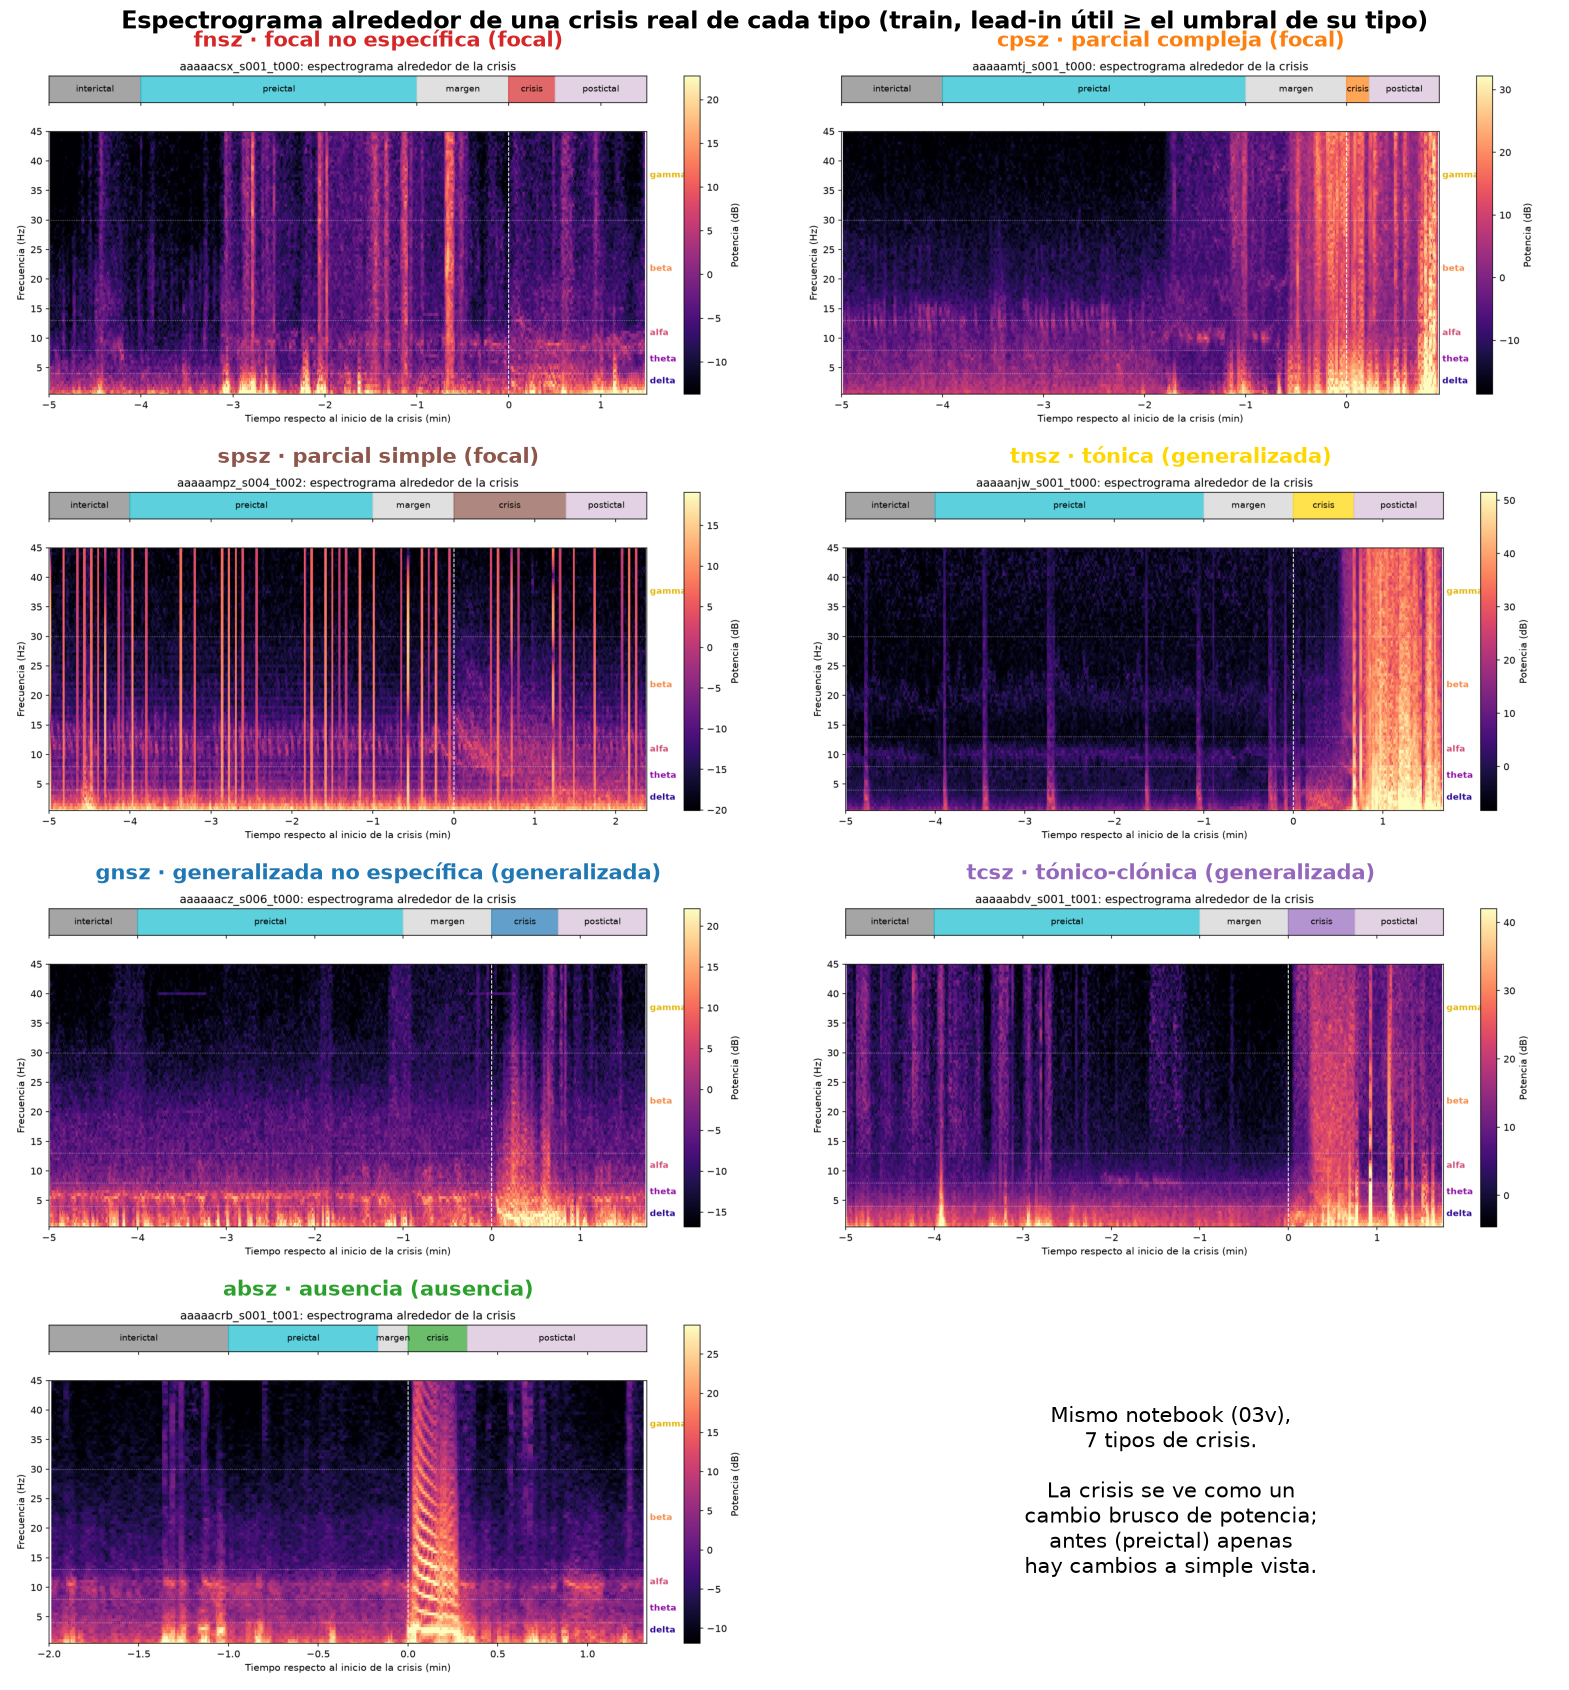

Galería guardada en fase_01\img\galeria_espectrogramas.png


In [5]:
import matplotlib.pyplot as plt
from tfm_comun.visual.colores import COLORES_ETIQUETA
from tfm_comun.dataset.tipos_crisis import info_tipo

figuras = {t: RUTA_OUTPUTS_FASE_01 / '03_visualizacion' / t / 'figuras' / 'espectrograma_crisis.png' for t in TIPOS}
faltan = [t for t, f in figuras.items() if not f.exists()]
assert not faltan, f'Falta el espectrograma de: {faltan}. Ejecuta antes la sección 3.'

columnas = 2
filas = (len(TIPOS) + 1 + columnas - 1) // columnas          # un hueco más para el texto final
fig, axes = plt.subplots(filas, columnas, figsize=(16, 4.3 * filas))
for ax, tipo in zip(axes.flat, TIPOS):
    ax.imshow(plt.imread(figuras[tipo]))
    ax.set_title(f'{tipo} · {info_tipo(tipo)["nombre"].removeprefix("de ")} ({grupo(tipo)})', fontsize=15,
                 fontweight='bold', color=COLORES_ETIQUETA[tipo])
for ax in axes.flat:
    ax.axis('off')
axes.flat[len(TIPOS)].text(0.5, 0.5, 'Mismo notebook (03v),\n7 tipos de crisis.\n\nLa crisis se ve como un\ncambio brusco de potencia;\n'
                           'antes (preictal) apenas\nhay cambios a simple vista.', ha='center', va='center', fontsize=15)
fig.suptitle('Espectrograma alrededor de una crisis real de cada tipo (train, lead-in útil ≥ el umbral de su tipo)',
             fontsize=17, fontweight='bold')
fig.tight_layout()
ruta_galeria = RUTA_FASE_01 / 'img' / 'galeria_espectrogramas.png'
ruta_galeria.parent.mkdir(exist_ok=True)
fig.savefig(ruta_galeria, dpi=110, bbox_inches='tight')
plt.show()
print(f'Galería guardada en {ruta_galeria.relative_to(RUTA_ALMA)}')

👀 **Cómo leer la galería.** Cada panel es el espectrograma de un tipo: **eje X** = tiempo, **eje Y** = frecuencia, **color** = potencia (más claro, más potencia). La crisis aparece como una **franja vertical clara**. Antes de ella (preictal) casi no hay cambios a simple vista: por eso la predicción necesita un modelo, no basta con mirar.